# Model 1: Simple CNN

## 1. Cấu hình và thư viện

In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, metrics, callbacks
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
import os
import hashlib
from collections import Counter

2026-10-15 20:04:45.499348: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-15 20:04:45.506016: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:479] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-15 20:04:45.515101: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:10575] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-15 20:04:45.515114: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1442] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-10-15 20:04:45.521260: I tensorflow/core/platform/cpu_feature_gua

In [2]:
DATA_DIR = Path("/home/pc/AAA/project/deepnn/G8_AI66A_DNN/data/raw")
TRAIN_DIR = DATA_DIR / "train"
VAL_DIR = DATA_DIR / "val"
TEST_DIR = DATA_DIR / "test"

IMG_SIZE = 224
BATCH_SIZE = 64
EPOCHS = 30
NUM_CLASSES = 4

## 2. Preprocessing

### 2.1 Loại bỏ ảnh trùng lặp

Lay data tu folder "raw" roi luu lai luon

In [3]:
SETS = ["train", "val", "test"]
class_names = ['CNV', 'DME', 'DRUSEN', 'NORMAL']

clean_samples = {se: [] for se in SETS}
seen_hash = {}
dup_count = Counter()

for se in ["test", "val", "train"]:
    se_dir = DATA_DIR / se
    
    for class_name in os.listdir(se_dir):
        class_dir = se_dir / class_name
        if not class_dir.is_dir():
            continue
            
        for img_path in class_dir.iterdir():
            if not img_path.is_file():
                continue
            
            # Tính mã MD5 của file ảnh
            with open(img_path, "rb") as f:
                file_hash = hashlib.md5(f.read()).hexdigest()
            
            if file_hash in seen_hash:
                kept_in = seen_hash[file_hash]
                dup_count[(se, kept_in)] += 1
                img_path.unlink() # xóa ảnh trùng khỏi ổ cứng
            else:
                seen_hash[file_hash] = se
                clean_samples[se].append((img_path, class_name))
            
print("Ảnh trùng bị loại:", sum(dup_count.values()))
for (drop_in, kept_in), n in dup_count.items():
    print(f"- {n} ảnh ở '{drop_in}' trùng với ảnh ở '{kept_in}'")
    
del seen_hash # Giải phóng bộ nhớ đệm hash sau khi dùng xong

clean_summary = pd.DataFrame({s: Counter(class_name for _, class_name in clean_samples[s]) for s in SETS}).fillna(0).astype(int)
clean_summary["total"] = clean_summary.sum(axis=1)
clean_summary.loc["TOTAL"] = clean_summary.sum()
print("\nSau khi làm sạch:")
clean_summary

Ảnh trùng bị loại: 0

Sau khi làm sạch:


,train,val,test,total
DRUSEN,5612,1722,879,8213
CNV,21034,7024,3678,31736
NORMAL,35002,10191,5135,50328
DME,7732,2278,1156,11166
TOTAL,69380,21215,10848,101443


In [4]:

train_ds = tf.keras.utils.image_dataset_from_directory(
    str(TRAIN_DIR),
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=True,
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    str(VAL_DIR),
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    str(TEST_DIR),
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)


Found 69380 files belonging to 4 classes.


2026-10-15 20:04:54.074355: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:998] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2026-10-15 20:04:54.095212: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:998] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2026-10-15 20:04:54.096714: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:998] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-

Found 21215 files belonging to 4 classes.
Found 10848 files belonging to 4 classes.


In [5]:
# Tối ưu hóa tốc độ đọc dữ liệu
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

### 2.2 Kiểm tra mất cân bằng lớp

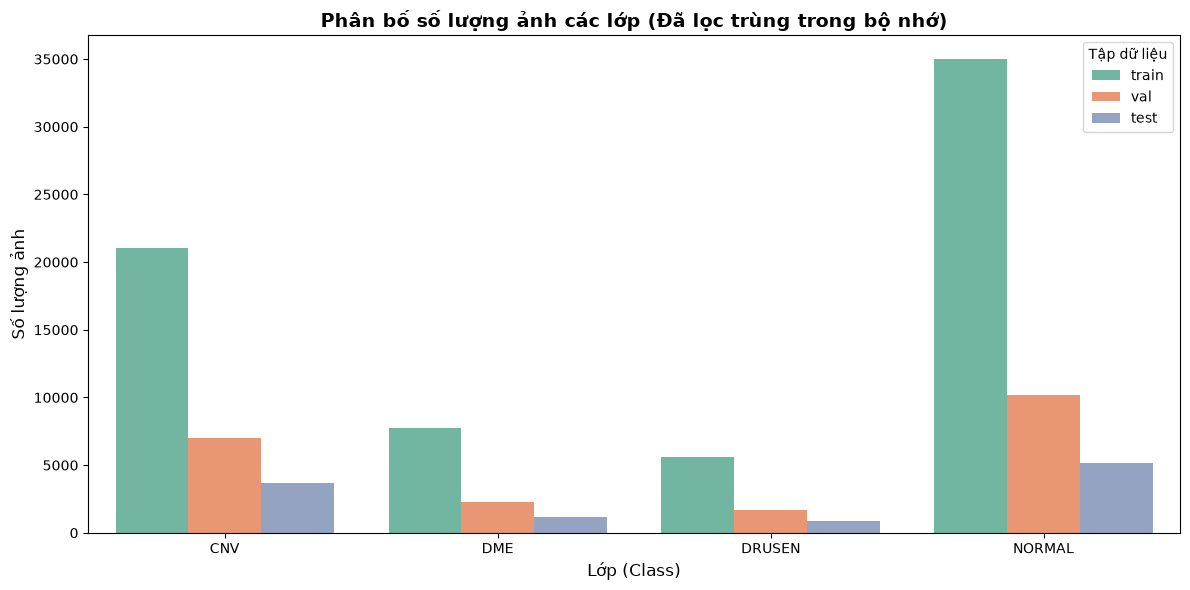

In [6]:
# Tạo DataFrame từ kết quả đếm để vẽ biểu đồ cho đẹp
data_summary = []
for split in SETS:
    # Đếm số lượng ảnh của từng lớp trong biến clean_samples
    split_counts = pd.Series([cls for _, cls in clean_samples[split]]).value_counts()
    for class_name in class_names:
        count = split_counts.get(class_name, 0)
        data_summary.append({"Split": split, "Class": class_name, "Count": count})
        
df_summary = pd.DataFrame(data_summary)

# Vẽ biểu đồ phân bố
plt.figure(figsize=(12, 6))
sns.barplot(data=df_summary, x="Class", y="Count", hue="Split", palette="Set2")
plt.title("Phân bố số lượng ảnh các lớp (Đã lọc trùng trong bộ nhớ)", fontsize=14, fontweight="bold")
plt.ylabel("Số lượng ảnh", fontsize=12)
plt.xlabel("Lớp (Class)", fontsize=12)
plt.legend(title="Tập dữ liệu")
plt.tight_layout()
plt.show()

=> Mất cân bằng (imbalanced) => Trước khi fit model ở phần sau thì tính class_weight rồi mới truyền vào model.fit()

### 2.3 Tính Mean và Std cho normalization

In [ ]:
normalization_layer = tf.keras.layers.Normalization(axis=-1)
normalization_layer.adapt(train_ds) # Tự động tính mean và variance

2026-10-15 20:05:01.769054: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


## 3. Xây dựng model

In [ ]:
model = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(15 / 360),
    layers.RandomZoom(
        height_factor=(-0.1, 0.1),
        width_factor=(-0.1, 0.1)
    ),
    layers.RandomBrightness(factor=0.2),
    layers.RandomContrast(factor=0.2),
    layers.RandomSaturation(factor=0.2),
    
    normalization_layer,   # Normalization 

    # CNN    
    layers.Conv2D(32, (3, 3), padding='same', use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(64, (3, 3), padding='same', use_bias=False),    
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(128, (3, 3), padding='same', use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),
    
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(NUM_CLASSES, activation="softmax")
])


In [9]:

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_brightness               │ (None, 224, 224, 3)    │             0 │
│ (RandomBrightness)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast                 │ (None, 224, 224, 3)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_saturation               │ (None, 224, 224, 3)    │             0 │
│ (RandomSaturation)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization (Normalization)   │ (None, 224, 224, 3)    │             7 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        33,02

 Total params: 127,979 (499.92 KB)

 Trainable params: 127,524 (498.14 KB)

 Non-trainable params: 455 (1.78 KB)

In [10]:
model.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy', metrics.F1Score(average='macro', name='f1_score')]
)

cb_list = [
    callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True),
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6)
]

## 4. Huan luyen

In [11]:
# Tính class weights để xử lý mất cân bằng dữ liệu
class_counts = [31736, 11166, 8213, 50328] # Theo thứ tự class_name: [CNV, DME, DRUSEN, NORMAL]
class_weights = compute_class_weight(
    class_weight='balanced', 
    classes=np.arange(NUM_CLASSES), 
    y=np.repeat(np.arange(NUM_CLASSES), class_counts)
)
class_weight_dict = dict(enumerate(class_weights))
print("Class weights:", class_weight_dict)

Class weights: {0: 0.7991161457020418, 1: 2.271247537166398, 2: 3.0878789723608913, 3: 0.5039093546336035}


In [12]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=cb_list,
    class_weight=class_weight_dict
)

Epoch 1/30


/home/pc/miniconda3/envs/pytorch_gpu/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
2026-10-15 20:05:04.093716: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:465] Loaded cuDNN version 8907


1085/1085 ━━━━━━━━━━━━━━━━━━━━ 119s 107ms/step - accuracy: 0.5670 - f1_score: 0.4283 - loss: 1.2000 - val_accuracy: 0.7250 - val_f1_score: 0.4832 - val_loss: 0.8261 - learning_rate: 0.0010
Epoch 2/30
1085/1085 ━━━━━━━━━━━━━━━━━━━━ 116s 107ms/step - accuracy: 0.6569 - f1_score: 0.4967 - loss: 1.0846 - val_accuracy: 0.7314 - val_f1_score: 0.4897 - val_loss: 0.8004 - learning_rate: 0.0010
Epoch 3/30
1085/1085 ━━━━━━━━━━━━━━━━━━━━ 115s 106ms/step - accuracy: 0.6698 - f1_score: 0.5185 - loss: 1.0428 - val_accuracy: 0.7646 - val_f1_score: 0.5079 - val_loss: 0.6968 - learning_rate: 0.0010
Epoch 4/30
1085/1085 ━━━━━━━━━━━━━━━━━━━━ 113s 104ms/step - accuracy: 0.6757 - f1_score: 0.5407 - loss: 1.0009 - val_accuracy: 0.5140 - val_f1_score: 0.2321 - val_loss: 1.7784 - learning_rate: 0.0010
Epoch 5/30
1085/1085 ━━━━━━━━━━━━━━━━━━━━ 113s 104ms/step - accuracy: 0.6877 - f1_score: 0.5675 - loss: 0.9455 - val_accuracy: 0.6098 - val_f1_score: 0.3841 - val_loss: 1.2714 - learning_rate: 0.0010
Epoch 6/30


### Vẽ learning curve để theo dõi

## 5. Danh gia tren tap test

In [14]:
y_true = np.concatenate([y for x, y in test_ds], axis=0)
y_true = np.argmax(y_true, axis=1)

y_pred_probs = model.predict(test_ds)
y_pred = np.argmax(y_pred_probs, axis=1)

  5/170 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step 

2026-10-15 20:47:06.057663: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


170/170 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step



Classification Report:
              precision    recall  f1-score   support

         CNV       0.97      0.71      0.82      3678
         DME       0.73      0.51      0.60      1156
      DRUSEN       0.44      0.75      0.56       879
      NORMAL       0.86      0.98      0.91      5135

    accuracy                           0.82     10848
   macro avg       0.75      0.74      0.72     10848
weighted avg       0.85      0.82      0.82     10848



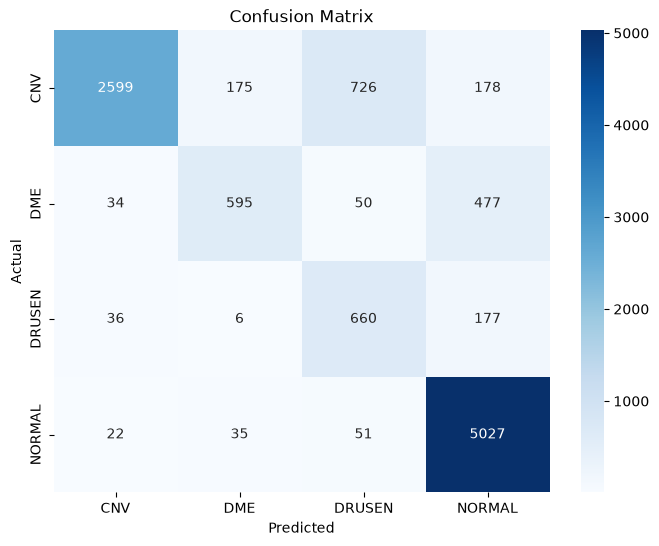

In [15]:
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

# Vẽ Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [16]:
# Lưu model
model.save('model1_simple_cnn.keras')